## Project IND320 - Part 3
Name: Abisan Sagayathasan 

 Github: Abisan-s , direct link: https://github.com/Abisan-s/IND320-reservoir-dashboard


 Streamlit link: https://ind320-reservoir-dashboard-ogxrr3mcdcp4x3bijhecfy.streamlit.app/

In [71]:
# packages used for geographic data and plotting
import geopandas as gpd
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

from shapely.geometry import Point

## Geographic areas

In this part I load the geographic areas that will be used for the weather analysis.

The electricity areas and NVE regions are loaded from local shapefiles (can be found in the data folder). These areas will later be used to randomly sample locations for the open meteo API.

In [72]:
#this part loads the electricity areas
electricity_areas = gpd.read_file(
    "../data/shapefiles/electricity_areas/Budområder.shp"
)

#this part loads the NVE regions
nve_regions = gpd.read_file(
    "../data/shapefiles/nve_regions/NVE_Region.shp"
)

In [73]:
#double check the first rows of the electricity areas
electricity_areas.head()

,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


In [74]:
#here we check the columns and coordinate systems
print("Electricity area columns:")
print(electricity_areas.columns)

print("\nElectricity areas CRS:")
print(electricity_areas.crs)

print("\nNVE region columns:")
print(nve_regions.columns)

print("\nNVE regions CRS:")
print(nve_regions.crs)

Electricity area columns:
Index(['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet',
       'geometry'],
      dtype='object')

Electricity areas CRS:
EPSG:25833

NVE region columns:
Index(['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED',
       'BESÃKSADR', 'ADRESSE', 'geometry'],
      dtype='object')

NVE regions CRS:
EPSG:25833


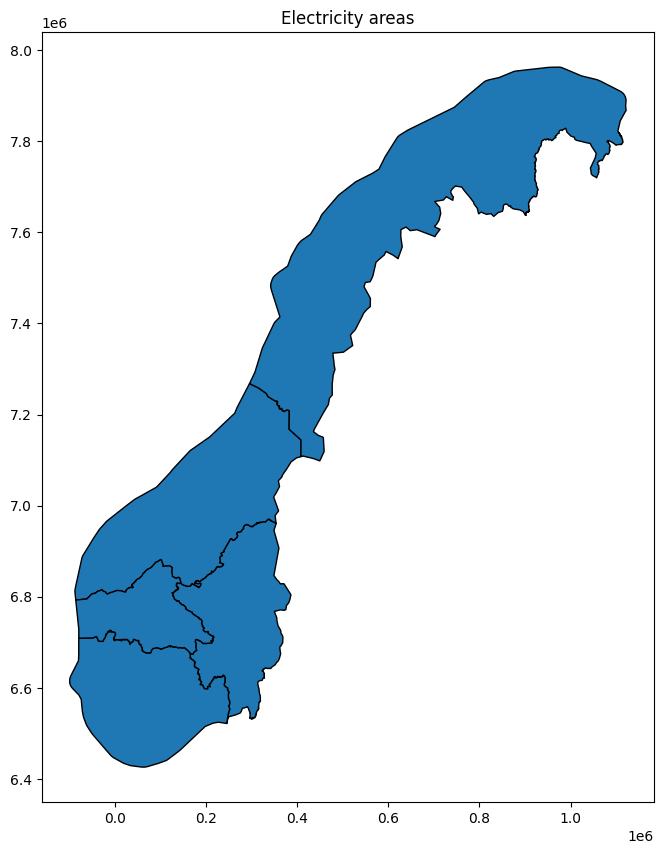

In [75]:
#a simple plot of the el-areas (budområder) to make sure the shapefile was loaded correctly
electricity_areas.plot(
    figsize=(8, 10),
    edgecolor="black"
)

plt.title("Electricity areas")
plt.show()

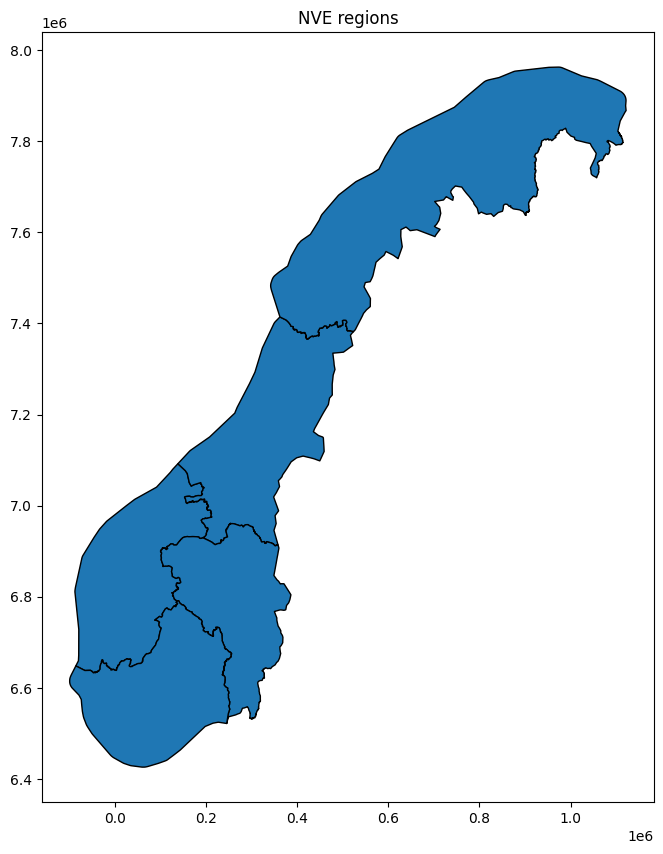

In [76]:
#plot the NVE regions
nve_regions.plot(
    figsize=(8, 10),
    edgecolor="black"
)

plt.title("NVE regions")
plt.show()

We can clearly see difference from the electricity areas and NVE regions. This tells us that the shapefiles has been looaded correctly 

In [77]:
#converts the coordinate systems to longitude and latitude since open meteo uses that
electricity_areas = electricity_areas.to_crs(
    epsg=4326
)

nve_regions = nve_regions.to_crs(
    epsg=4326
)

print("Electricity areas:", electricity_areas.crs)
print("NVE regions:", nve_regions.crs)

Electricity areas: EPSG:4326
NVE regions: EPSG:4326


In [78]:
#shows the available values in each column and their names
for column in electricity_areas.columns:
    if column != "geometry":
        print(column)
        print(electricity_areas[column].unique())
        print()

objectid
[1. 2. 3. 4. 5.]

budomr
['NO 1' 'NO 2' 'NO 3' 'NO 4' 'NO 5']

globalid
[nan]

st_area(sh
[6.05290186e+10 6.87596890e+10 1.04219852e+11 2.03250012e+11
 3.33487028e+10]

st_perimet
[1657761.14830992 1256473.06679791 1773322.62694724 3385499.24098949
 1106762.34231224]



In [79]:
#here we select the electricity area NO3
no3 = electricity_areas[
    electricity_areas["budomr"] == "NO 3"
].copy()

no3

,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((10.87378 65.41986, 10.98433 65.40083..."


In [80]:
#double check that only NO3 was selected and no other areas
print(no3["budomr"].unique())

['NO 3']


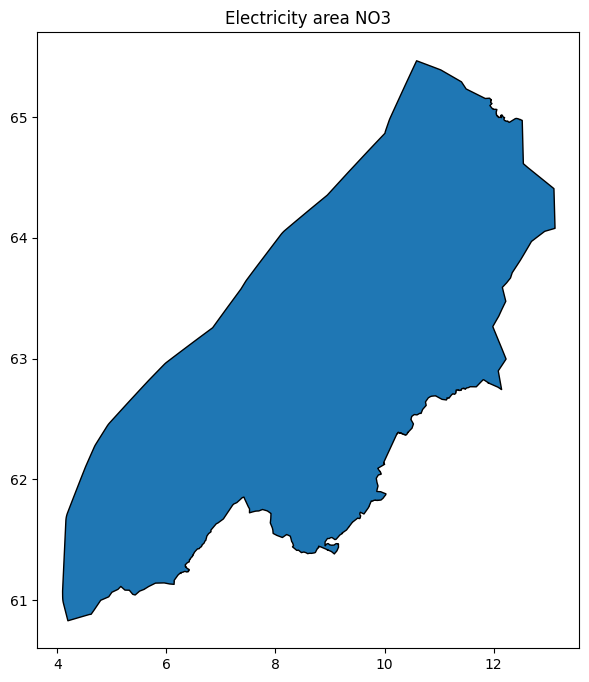

In [81]:
# plots NO3 to check that the correct area was selected
no3.plot(
    figsize=(7, 8),
    edgecolor="black"
)

plt.title("Electricity area NO3")
plt.show()

In [82]:
#this part generates random points inside a geographic region.
def sample_random_points(region_geometry, n=1000, seed=42):

    np.random.seed(seed)

    #gets the boundaries of the region
    min_x, min_y, max_x, max_y = region_geometry.bounds

    points = []

    while len(points) < n:

        random_point = Point(
            np.random.uniform(min_x, max_x),
            np.random.uniform(min_y, max_y)
        )

        #make sure to only keep the points inside the selected region
        if region_geometry.contains(random_point):
            points.append(random_point)

    return points

In [83]:
#this part combines all geometry belonging to NO3 into one shape
no3_geometry = no3.geometry.union_all()

In [84]:
#we generate 1000 random locations inside NO3
no3_points = sample_random_points(
    no3_geometry,
    n=1000,
    seed=42
)

print("Number of locations:", len(no3_points))

Number of locations: 1000


In [85]:
#converts the sampled points to longitude and latitude
no3_locations = pd.DataFrame({
    "longitude": [point.x for point in no3_points],
    "latitude": [point.y for point in no3_points]
})

no3_locations.head()

,longitude,latitude
0,10.696007,63.609226
1,5.496070,61.556673
2,9.514425,64.116560
3,5.729051,61.683768
4,7.987149,62.183731


In [86]:
#this part creates a geodata frame so we can plot the locations
no3_points_gdf = gpd.GeoDataFrame(
    no3_locations,
    geometry=gpd.points_from_xy(
        no3_locations["longitude"],
        no3_locations["latitude"]
    ),
    crs="EPSG:4326"
)

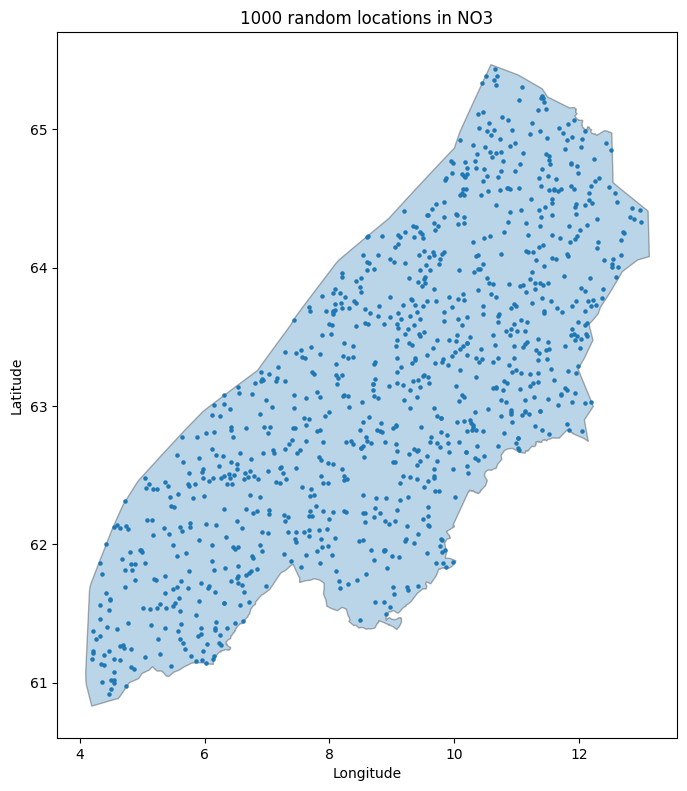

In [87]:
#plots the random locations inside NO3
fig, ax = plt.subplots(
    figsize=(8, 10)
)

no3.plot(
    ax=ax,
    edgecolor="black",
    alpha=0.3
)

no3_points_gdf.plot(
    ax=ax,
    markersize=5
)

plt.title("1000 random locations in NO3")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [88]:
#function for creating random locations for a selected region
def get_region_locations(
    areas_gdf,
    region_column,
    region_name,
    n=1000,
    seed=42
):

    #selects the requested region
    selected_region = areas_gdf[
        areas_gdf[region_column] == region_name
    ].copy()

    if selected_region.empty:
        raise ValueError(
            f"Region {region_name} was not found."
        )

    #combines all polygons belonging to the region
    region_geometry = selected_region.geometry.union_all()

    #this part generates random points inside the region
    points = sample_random_points(
        region_geometry,
        n=n,
        seed=seed
    )

    locations = pd.DataFrame({
        "region": region_name,
        "longitude": [point.x for point in points],
        "latitude": [point.y for point in points]
    })

    return locations

In [89]:
#creates 1000 random locations for each electricity area NO1-NO5
electricity_locations = []

for region in [
    "NO 1",
    "NO 2",
    "NO 3",
    "NO 4",
    "NO 5"
]:

    region_locations = get_region_locations(
        electricity_areas,
        region_column="budomr",
        region_name=region,
        n=1000,
        seed=42
    )

    electricity_locations.append(
        region_locations
    )

electricity_locations = pd.concat(
    electricity_locations,
    ignore_index=True
)

electricity_locations.head()

,region,longitude,latitude
0,NO 1,11.567191,61.196420
1,NO 1,10.930558,61.641538
2,NO 1,9.486485,60.895772
3,NO 1,10.107667,59.945737
4,NO 1,10.982790,59.328449


In [90]:
#double check that each area has 1000 locations
electricity_locations["region"].value_counts()

region
NO 1    1000
NO 2    1000
NO 3    1000
NO 4    1000
NO 5    1000
Name: count, dtype: int64

In [91]:
#in this part we do the same for the NVE regions
#shows the available values in the NVE region shapefile
for column in nve_regions.columns:
    if column != "geometry":
        print(column)
        print(nve_regions[column].unique())
        print()

OBJECTID
[1. 2. 3. 4. 5.]

REGION
['RV' 'RM' 'RN' 'RÃ\x98' 'RS']

REGIONNAVN
['Region Vest' 'Region Midt-Norge' 'Region Nord' 'Region Ã\x98st'
 'Region SÃ¸r']

POSTNUMMER
['6801' '7030' '8514' '2307' '3103']

POSTSTED
['FÃ¸rde' 'Trondheim' 'Narvik' 'Hamar' 'TÃ¸nsberg']

BESÃKSADR
['Naustdalsveien 1B' 'Abelsgate 9, Trondheim' 'Kongensgate 52-54'
 'Vangsvegen 73' 'Anton Jenssens gate 7']

ADRESSE
['Postboks 53' 'Abelsgate 9' 'Kongensgate 52-54' 'Postboks 4223'
 'Postboks 2124']



In [92]:
#need to use the utf-8 encoding so that RÃ\x98' appears as RØ
#loads the NVE regions with the correct text encoding
nve_regions = gpd.read_file(
    "../data/shapefiles/nve_regions/NVE_Region.shp",
    encoding="utf-8"
)

nve_regions = nve_regions.to_crs(
    epsg=4326
)

print(nve_regions["REGION"].unique())
print(nve_regions["REGIONNAVN"].unique())

['RV' 'RM' 'RN' 'RØ' 'RS']
['Region Vest' 'Region Midt-Norge' 'Region Nord' 'Region Øst' 'Region Sør']


In [93]:
#this part creates the three precipitation regions used in the project
east = nve_regions[
    nve_regions["REGION"].isin(["RS", "RØ"])
].copy()

north = nve_regions[
    nve_regions["REGION"].isin(["RM", "RN"])
].copy()

west = nve_regions[
    nve_regions["REGION"] == "RV"
].copy()

print("East parts:", east["REGION"].tolist())
print("North parts:", north["REGION"].tolist())
print("West parts:", west["REGION"].tolist())

East parts: ['RØ', 'RS']
North parts: ['RM', 'RN']
West parts: ['RV']


In [94]:
#combines the subregions into the final precipitation regions
precipitation_regions = {
    "East": east.geometry.union_all(),
    "North": north.geometry.union_all(),
    "West": west.geometry.union_all()
}

In [95]:
#generates 1000 random locations in each precipitation region
precipitation_locations = []

for region_name, region_geometry in precipitation_regions.items():

    points = sample_random_points(
        region_geometry,
        n=1000,
        seed=42
    )

    region_locations = pd.DataFrame({
        "region": region_name,
        "longitude": [point.x for point in points],
        "latitude": [point.y for point in points]
    })

    precipitation_locations.append(region_locations)

precipitation_locations = pd.concat(
    precipitation_locations,
    ignore_index=True
)

precipitation_locations.head()

,region,longitude,latitude
0,East,10.615155,60.715135
1,East,5.767416,58.529294
2,East,9.513603,61.255413
3,East,5.984617,58.664643
4,East,8.089771,59.197072


In [96]:
#double check that every NVE region has 1000 locations
precipitation_locations["region"].value_counts()

region
East     1000
North    1000
West     1000
Name: count, dtype: int64

## Open-Meteo historical weather data

In this part I use the open meteo API to retrieve hourly ERA5 analysis data.

The geographic locations are taken from the random locations generated inside the NVE regions and electricity areas.

In [97]:
import requests
#to make sure that the API call works, i start by trying one location first
#selects one of the sampled locations inside NO3
no3_test_location = electricity_locations[
    electricity_locations["region"] == "NO 3"
].iloc[0]

latitude = no3_test_location["latitude"]
longitude = no3_test_location["longitude"]

print("Latitude:", latitude)
print("Longitude:", longitude)

Latitude: 63.60922624603101
Longitude: 10.696007292292887


In [98]:
# Open-Meteo Historical Weather API endpoint
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",
    "timezone": "UTC"
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)

Status code: 200


Status code:200 tells us that ERA5 has hourly data and can show 2024 without problems

In [99]:
#converts the API response to JSON
weather_json = response.json()

weather_json.keys()

dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

In [100]:
weather_json["hourly"].keys()

dict_keys(['time', 'temperature_2m', 'precipitation'])

In [101]:
#converts the hourly weather data to a pandas dataframe
test_weather_df = pd.DataFrame(
    weather_json["hourly"]
)

test_weather_df["time"] = pd.to_datetime(
    test_weather_df["time"]
)

test_weather_df.head()

,time,temperature_2m,precipitation
0,2024-01-01 00:00:00,-2.7,0.0
1,2024-01-01 01:00:00,-2.7,0.0
2,2024-01-01 02:00:00,-2.5,0.0
3,2024-01-01 03:00:00,-2.3,0.0
4,2024-01-01 04:00:00,-2.3,0.0


In [102]:
#checks the structure of the downloaded weather data
test_weather_df.info() 
print("\n----------------------------------------------------")

#checks if there are missing values
print("Missing values:")
test_weather_df.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   time            168 non-null    datetime64[ns]
 1   temperature_2m  168 non-null    float64       
 2   precipitation   168 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 4.1 KB

----------------------------------------------------
Missing values:


time              0
temperature_2m    0
precipitation     0
dtype: int64

In [103]:
#this part downloads hourly ERA5 weather data for one sampled location
#inside the selected electricity area. After confirming that it works. i apply it to the rest

def get_weather_data(region, start_date, end_date):

    #finds all sampled locations for the selected region
    region_locations = electricity_locations[
        electricity_locations["region"] == region
    ]

    if region_locations.empty:
        raise ValueError(
            f"Region {region} was not found."
        )

    #uses the first sampled location in the region
    location = region_locations.iloc[0]

    latitude = location["latitude"]
    longitude = location["longitude"]

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation",
        "models": "era5",
        "timezone": "UTC"
    }

    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    weather_json = response.json()

    #converts the hourly response to a dataframe
    weather_df = pd.DataFrame(
        weather_json["hourly"]
    )

    weather_df["time"] = pd.to_datetime(
        weather_df["time"]
    )

    #adds information about the selected location
    weather_df["region"] = region
    weather_df["latitude"] = latitude
    weather_df["longitude"] = longitude

    return weather_df

In [104]:
#downloads hourly ERA5 data for the whole NO3 in 2024
no3_weather_2024 = get_weather_data(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

no3_weather_2024.head()

,time,temperature_2m,precipitation,region,latitude,longitude
0,2024-01-01 00:00:00,-2.7,0.0,NO 3,63.609226,10.696007
1,2024-01-01 01:00:00,-2.7,0.0,NO 3,63.609226,10.696007
2,2024-01-01 02:00:00,-2.5,0.0,NO 3,63.609226,10.696007
3,2024-01-01 03:00:00,-2.3,0.0,NO 3,63.609226,10.696007
4,2024-01-01 04:00:00,-2.3,0.0,NO 3,63.609226,10.696007


In [105]:
#checks the amount and time period of the downloaded data
print("Number of rows:", len(no3_weather_2024))
print("First date:", no3_weather_2024["time"].min())
print("Last date:", no3_weather_2024["time"].max())

Number of rows: 8784
First date: 2024-01-01 00:00:00
Last date: 2024-12-31 23:00:00


We have 24 hour data and 2024 is a leap year. 24 x 366 = 8784 rows of data

## Outliers and anomalies

In [106]:
#this part creates daily average precipitation from the hourly data
daily_precipitation = (
    no3_weather_2024
    .set_index("time")["precipitation"]
    .resample("D")
    .mean()
    .reset_index()
)

daily_precipitation.head()

,time,precipitation
0,2024-01-01,0.000000
1,2024-01-02,0.000000
2,2024-01-03,0.000000
3,2024-01-04,0.000000
4,2024-01-05,0.041667


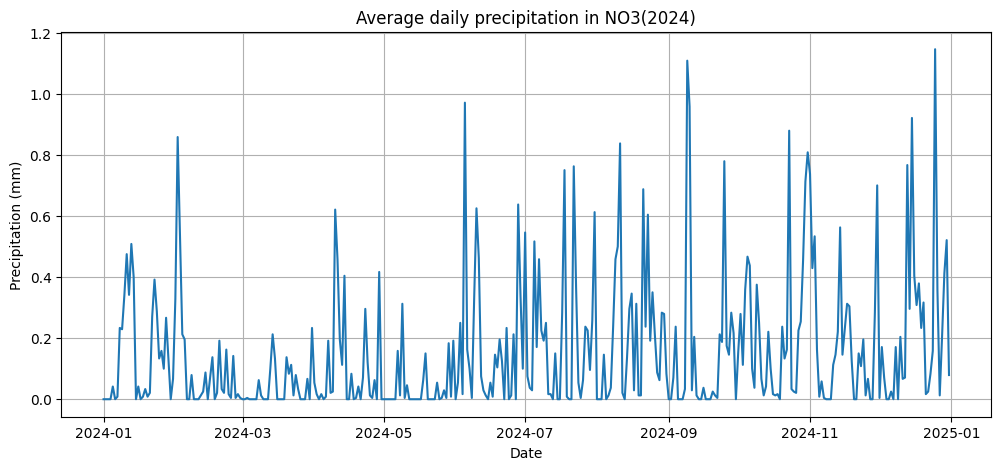

In [107]:
#plots the average precipitation over time
plt.figure(figsize=(12, 5))

plt.plot(
    daily_precipitation["time"],
    daily_precipitation["precipitation"]
)

plt.title("Average daily precipitation in NO3(2024)")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")

plt.grid(True)

plt.show()

In [108]:
#importing the DCT functions
from scipy.fft import dct, idct

#this part gets the daily precipitation values as a numpy array
precip_values = daily_precipitation[
    "precipitation"
].to_numpy()

#transforms the signal to the frequency domain
precip_dct = dct(
    precip_values,
    norm="ortho"
)

precip_dct[:10]

array([ 2.94393712, -0.94265434,  0.1236556 ,  0.37099438,  0.48750837,
       -0.01938505,  0.10998737,  0.12716106,  0.25791603, -0.15568846])

In [109]:
#making the highpass filter 
#removes the lowest-frequency components
cutoff = 10

filtered_dct = precip_dct.copy()

filtered_dct[:cutoff] = 0

In [110]:
#transforms the filtered signal back to the time domain
satv = idct(
    filtered_dct,
    norm="ortho"
)

daily_precipitation["SATV"] = satv

daily_precipitation.head()

,time,precipitation,SATV
0,2024-01-01,0.000000,-0.180440
1,2024-01-02,0.000000,-0.180308
2,2024-01-03,0.000000,-0.180044
3,2024-01-04,0.000000,-0.179648
4,2024-01-05,0.041667,-0.137455


In [111]:
#this part calculates robust statistics from the SATV values
satv_median = np.median(
    daily_precipitation["SATV"]
)

mad = np.median(
    np.abs(
        daily_precipitation["SATV"] - satv_median
    )
)

#converts median absolute value to a robust estimate of standard deviation
robust_std = 1.4826 * mad

print("SATV median:", satv_median)
print("Robust standard deviation:", robust_std)

SATV median: -0.053756512128809504
Robust standard deviation: 0.15190855251875382


In [112]:
#number of standard deviations used for the SPC boundaries
n_std = 3

lower_boundary = (
    satv_median - n_std * robust_std
)

upper_boundary = (
    satv_median + n_std * robust_std
)

print("Lower boundary:", lower_boundary)
print("Upper boundary:", upper_boundary)

Lower boundary: -0.509482169685071
Upper boundary: 0.401969145427452


### Precipitation and SPC

In [113]:
#this part finds values outside the SPC boundaries
daily_precipitation["outlier"] = (
    (daily_precipitation["SATV"] < lower_boundary) |
    (daily_precipitation["SATV"] > upper_boundary)
)

print(
    "Number of outliers:",
    daily_precipitation["outlier"].sum()
)

Number of outliers: 22


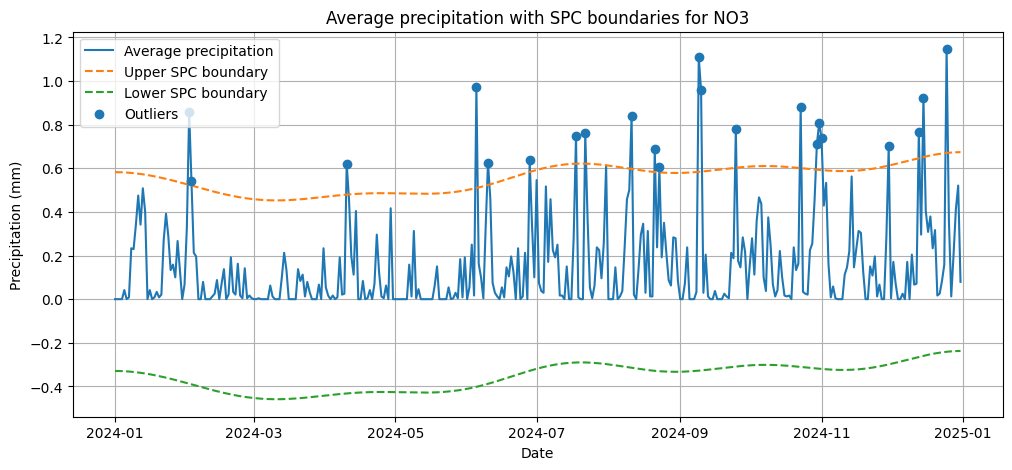

In [114]:
#plots precipitation with SPC boundaries and detected outliers
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    daily_precipitation["time"],
    daily_precipitation["precipitation"],
    label="Average precipitation"
)

#converts SATV boundaries back around the precipitation level
center_line = (
    daily_precipitation["precipitation"]
    - daily_precipitation["SATV"]
)

upper_curve = center_line + upper_boundary
lower_curve = center_line + lower_boundary

ax.plot(
    daily_precipitation["time"],
    upper_curve,
    linestyle="--",
    label="Upper SPC boundary"
)

ax.plot(
    daily_precipitation["time"],
    lower_curve,
    linestyle="--",
    label="Lower SPC boundary"
)

#only the original precipitation values are shown as outliers
outliers = daily_precipitation[
    daily_precipitation["outlier"]
]

ax.scatter(
    outliers["time"],
    outliers["precipitation"],
    label="Outliers",
    zorder=3
)

ax.set_title(
    "Average precipitation with SPC boundaries for NO3"
)

ax.set_xlabel("Date")
ax.set_ylabel("Precipitation (mm)")

ax.legend()
ax.grid(True)

plt.show()

The SPC boundaries are calculated using the SATV and robust statistics. Values outside these boundaries are marked as outliers on the original precipitation series.

This makes it easier to identify unusually high or low precipitation values while accounting for seasonal variation.

In [115]:
#this part performs DCT high pass filtering and SPC outlier detection
#on daily average precipitation.

def precipitation_spc_analysis(
    weather_df,
    cutoff=10,
    n_std=3
):
    #creates a daily average precipitation
    daily_data = (
        weather_df
        .set_index("time")["precipitation"]
        .resample("D")
        .mean()
        .reset_index()
    )

    precipitation_values = daily_data[
        "precipitation"
    ].to_numpy()

    #transforms the precipitation signal
    precipitation_dct = dct(
        precipitation_values,
        norm="ortho"
    )

    filtered_dct = precipitation_dct.copy()

    #removes low-frequency components
    filtered_dct[:cutoff] = 0

    satv = idct(
        filtered_dct,
        norm="ortho"
    )

    daily_data["SATV"] = satv

    #calculates robust statistics
    satv_median = np.median(satv)

    mad = np.median(
        np.abs(
            satv - satv_median
        )
    )

    # 1 / 0,67449 = 1.4826. This is used for scaling
    robust_std = 1.4826 * mad

    lower_boundary = (
        satv_median - n_std * robust_std
    )

    upper_boundary = (
        satv_median + n_std * robust_std
    )

    # identifies outliers using SATV
    daily_data["outlier"] = (
        (daily_data["SATV"] < lower_boundary) |
        (daily_data["SATV"] > upper_boundary)
    )

    #converts the SATV boundaries back to the original scale
    center_line = (
        daily_data["precipitation"]
        - daily_data["SATV"]
    )

    upper_curve = (
        center_line + upper_boundary
    )

    lower_curve = (
        center_line + lower_boundary
    )

    #creates the final plot
    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    ax.plot(
        daily_data["time"],
        daily_data["precipitation"],
        label="Average precipitation"
    )

    ax.plot(
        daily_data["time"],
        upper_curve,
        linestyle="--",
        label="Upper SPC boundary"
    )

    ax.plot(
        daily_data["time"],
        lower_curve,
        linestyle="--",
        label="Lower SPC boundary"
    )

    outliers = daily_data[
        daily_data["outlier"]
    ]

    ax.scatter(
        outliers["time"],
        outliers["precipitation"],
        label="Outliers",
        zorder=3
    )

    ax.set_title(
        "Average precipitation with SPC boundaries"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()
    ax.grid(True)

    summary = {
        "cutoff": cutoff,
        "n_std": n_std,
        "number_of_outliers": int(
            daily_data["outlier"].sum()
        ),
        "lower_boundary": lower_boundary,
        "upper_boundary": upper_boundary
    }

    return fig, summary

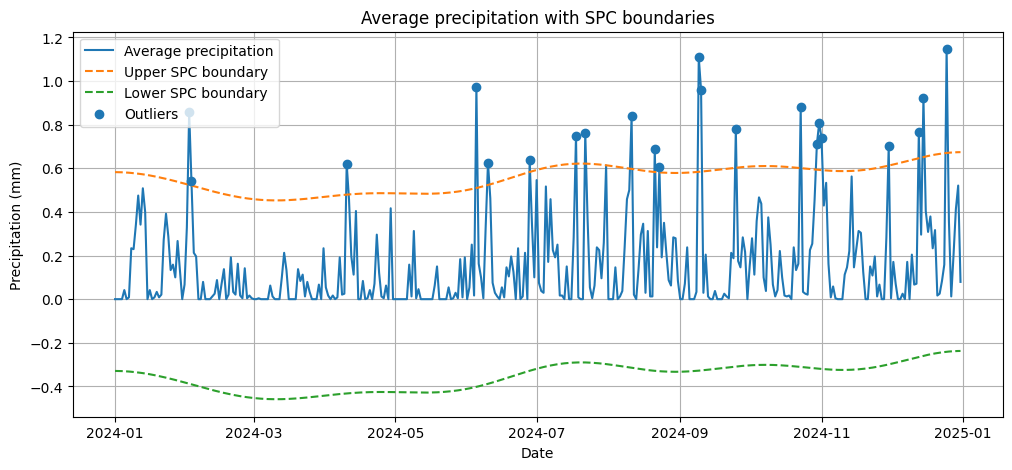

{'cutoff': 10,
 'n_std': 3,
 'number_of_outliers': 22,
 'lower_boundary': np.float64(-0.509482169685071),
 'upper_boundary': np.float64(0.401969145427452)}

In [116]:
#tests the precipitation SPC function
precipitation_fig, precipitation_summary = (
    precipitation_spc_analysis(
        no3_weather_2024,
        cutoff=10,
        n_std=3
    )
)

plt.show()

precipitation_summary

As we see the final analysis identified 22 outliers using a DCT cutoff of 10 and three standard deviations.

The SATV is only used internally to calculate the SPC boundaries and detect unusual observations. The final plot therefore shows the original precipitation values, the SPC boundaries and the detected outliers.

### Temperature and LOF

In [117]:
#creates daily average temperature from the hourly data
daily_temperature = (
    no3_weather_2024
    .set_index("time")["temperature_2m"]
    .resample("D")
    .mean()
    .reset_index()
)

daily_temperature.head()

,time,temperature_2m
0,2024-01-01,-2.904167
1,2024-01-02,-5.933333
2,2024-01-03,-7.254167
3,2024-01-04,-10.091667
4,2024-01-05,-10.508333


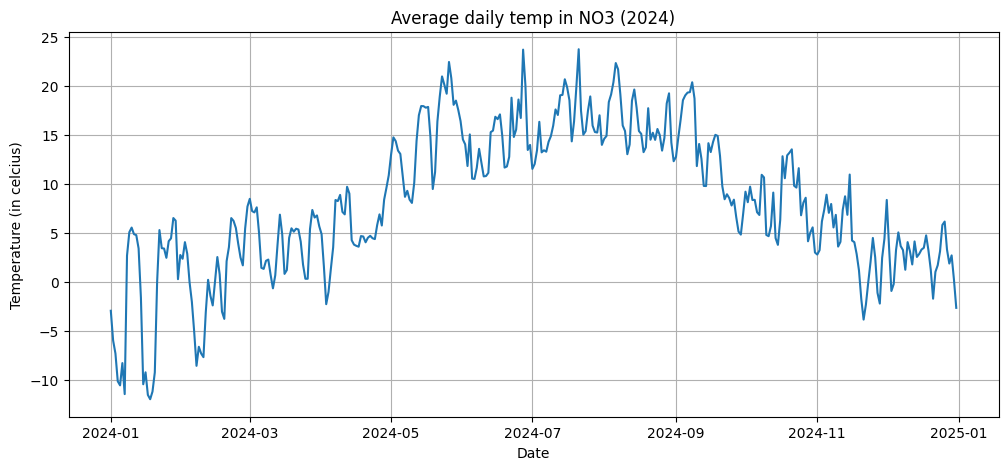

In [118]:
#plots the average temperature over time
plt.figure(figsize=(12, 5))

plt.plot(
    daily_temperature["time"],
    daily_temperature["temperature_2m"]
)

plt.title("Average daily temp in NO3 (2024)")
plt.xlabel("Date")
plt.ylabel("Temperature (in celcius)")

plt.grid(True)
plt.show()

In [119]:
#importing local utlier factor (LOF)
from sklearn.neighbors import LocalOutlierFactor

#reshapes the temperature values for LOF
temperature_values = daily_temperature[
    "temperature_2m"
].to_numpy().reshape(-1, 1)

#default proportion of anomalies is 1%
lof = LocalOutlierFactor(
    contamination=0.01
)

lof_labels = lof.fit_predict(
    temperature_values
)

#-1 means anomaly and 1 means normal
daily_temperature["anomaly"] = (
    lof_labels == -1
)

print(
    "Number of anomalies:",
    daily_temperature["anomaly"].sum()
)

Number of anomalies: 4


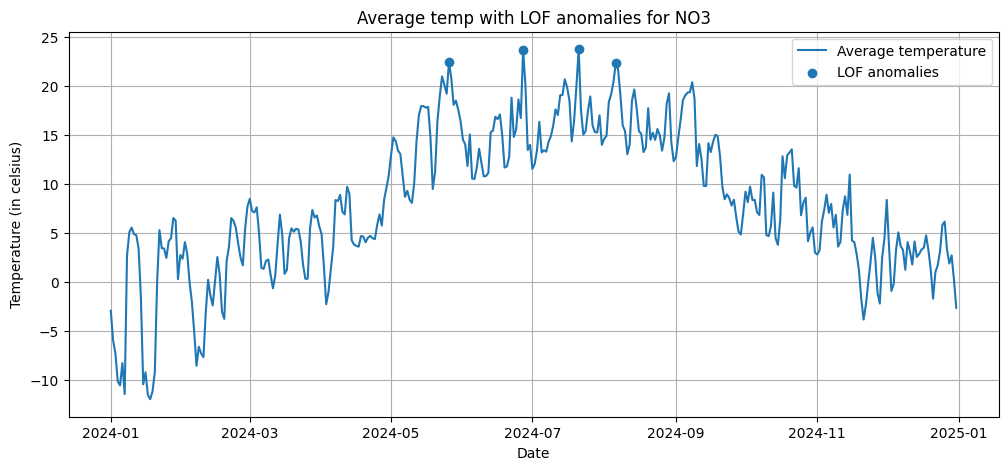

In [120]:
#here i plot the temperature and marks the LOF anomalies
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    daily_temperature["time"],
    daily_temperature["temperature_2m"],
    label="Average temperature"
)

anomalies = daily_temperature[
    daily_temperature["anomaly"]
]

ax.scatter(
    anomalies["time"],
    anomalies["temperature_2m"],
    label="LOF anomalies",
    zorder=3
)

ax.set_title(
    "Average temp with LOF anomalies for NO3"
)

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (in celsius)")

ax.legend()
ax.grid(True)

plt.show()

As we can see the LOF analysis detects a small number of temperature anomalies based on the local density of the observations.

The default outlier proportion is set to 1%, which gives a small number of unusual temperature values compared with the rest of the year.

In [121]:
#here i detect the temperature anomalies using LOF

def temperature_lof_analysis(
    weather_df,
    proportion=0.01
):
    #creates daily average temperature
    daily_data = (
        weather_df
        .set_index("time")["temperature_2m"]
        .resample("D")
        .mean()
        .reset_index()
    )

    temperature_values = daily_data[
        "temperature_2m"
    ].to_numpy().reshape(-1, 1)

    #applies LOF with the selected outlier proportion
    lof = LocalOutlierFactor(
        contamination=proportion
    )

    labels = lof.fit_predict(
        temperature_values
    )

    daily_data["anomaly"] = (
        labels == -1
    )

    #creates the final plot
    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    ax.plot(
        daily_data["time"],
        daily_data["temperature_2m"],
        label="Average temperature"
    )

    anomalies = daily_data[
        daily_data["anomaly"]
    ]

    ax.scatter(
        anomalies["time"],
        anomalies["temperature_2m"],
        label="LOF anomalies",
        zorder=3
    )

    ax.set_title(
        "Average temp with LOF anomalies"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (in celsius)")

    ax.legend()
    ax.grid(True)

    summary = {
        "proportion": proportion,
        "number_of_anomalies": int(
            daily_data["anomaly"].sum()
        )
    }

    return fig, summary

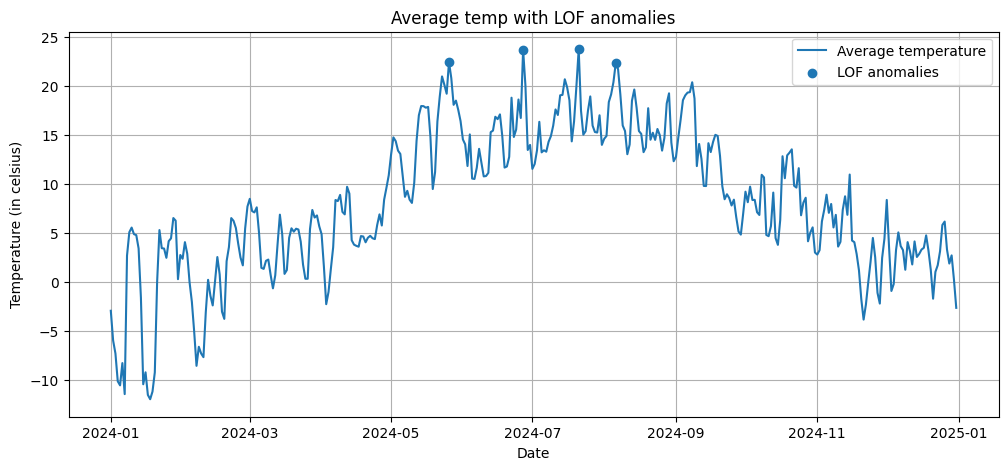

{'proportion': 0.01, 'number_of_anomalies': 4}

In [122]:
#this part tests the LOF temperature function
temperature_fig, temperature_summary = (
    temperature_lof_analysis(
        no3_weather_2024,
        proportion=0.01
    )
)

plt.show()

temperature_summary

The LOF analysis detected 4 temperature anomalies using an outlier proportion of 1%.

The detected points represent temperatures that differ from the local pattern of the rest of the observations. The remaining values are treated as normal observations.

## Seasonal trend decomposition using LOESS (STL)

In this part i decompose the reservoir filling level into trend, seasonal variation and residual components using STL.

In [123]:
#loads the reservoir data used for the STL analysis
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(
    url,
    timeout=30
)

response.raise_for_status()

reservoir_data = response.json()

reservoir_df = pd.DataFrame(
    reservoir_data
)

#renames the columns to the english names used earlier
reservoir_df = reservoir_df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

#converts date to datetime
reservoir_df["date"] = pd.to_datetime(
    reservoir_df["date"]
)

reservoir_df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


In [124]:
#importing STL decomposition
from statsmodels.tsa.seasonal import STL

#selects one reservoir area for the STL analysis
stl_data = reservoir_df[
    (reservoir_df["area_type"] == "NO") &
    (reservoir_df["area_number"] == 0)
].copy()

stl_data = stl_data.sort_values(
    "date"
)

stl_data = stl_data[
    ["date", "fill_level"]
].dropna()

stl_data.head()

,date,fill_level
9941,1995-01-08,0.603830
9885,1995-01-15,0.578233
9848,1995-01-22,0.558350
9822,1995-01-29,0.530596
9887,1995-02-05,0.502755


In [125]:
#this part prepares the filling level as a weekly time series
stl_series = (
    stl_data
    .set_index("date")["fill_level"]
    .asfreq("7D")
)

#this part fills small gaps if there are any missing weekly observations
stl_series = stl_series.interpolate()

stl_series.head()

date
1995-01-08    0.603830
1995-01-15    0.578233
1995-01-22    0.558350
1995-01-29    0.530596
1995-02-05    0.502755
Freq: 7D, Name: fill_level, dtype: float64

In [126]:
#here i perform the STL decomposition on the reservoir filling level

def stl_analysis(
    series,
    seasonal=13,
    trend=53,
    robust=True
):
    #STL uses a yearly period for weekly data (52 weeks)
    stl = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    #creating the decomposition plot
    fig = result.plot()

    fig.set_size_inches(12, 8)
    fig.suptitle(
        "STL decomposition of reservoir filling level",
        y=1.02
    )

    return fig, result

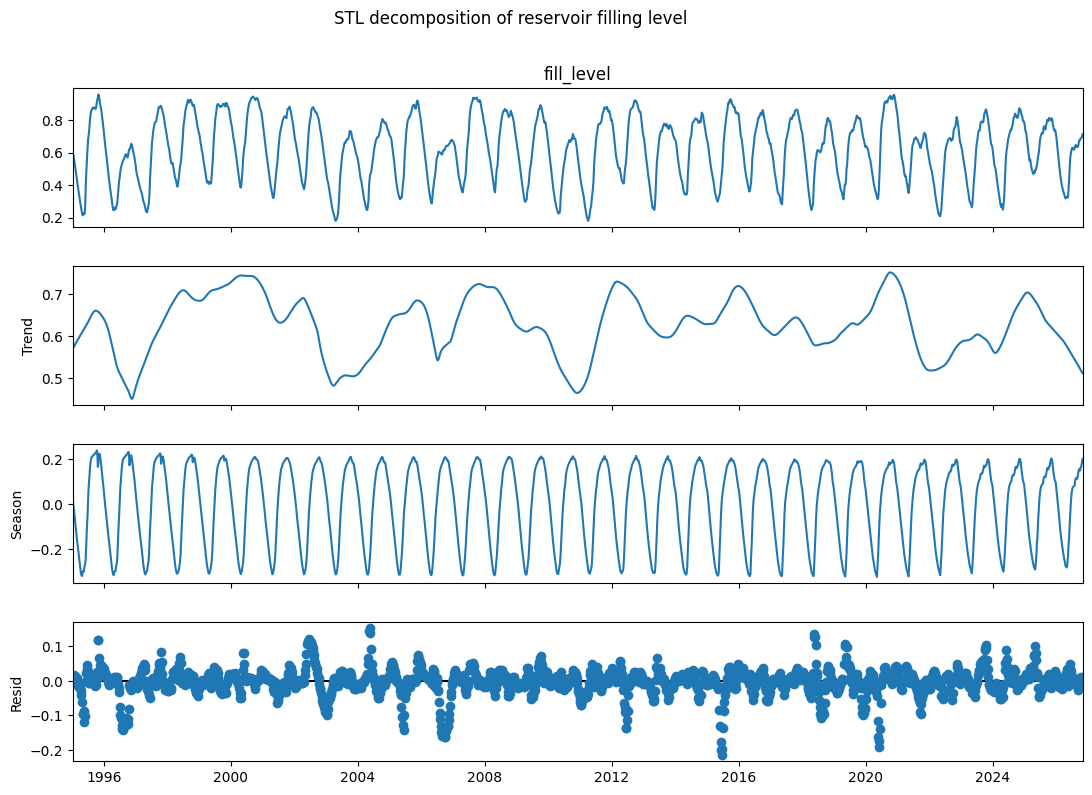

In [127]:
#tests the STL function
stl_fig, stl_result = stl_analysis(
    stl_series,
    seasonal=13,
    trend=53,
    robust=True
)

plt.show()

The STL decomposition separates the filling level into trend, seasonal variation and residual components.

We can see that the seasonal component shows a yearly pattern, while the trend captures slower changes in the reservoir filling level over time. The residual component contains the remaining short term variation that is not explained by the trend or seasonality.

## Spectrogram

In [128]:
#in this part i create a spectogram of the filling level  
from scipy.signal import spectrogram

def spectrogram_analysis(
    series,
    window_length=128,
    overlap=64
):
    values = series.to_numpy()

    #here i calculate the spectrogram
    frequencies, times, power = spectrogram(
        values,
        fs=1,
        nperseg=window_length,
        noverlap=overlap
    )

    #simple plot
    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    mesh = ax.pcolormesh(
        times,
        frequencies,
        power,
        shading="auto"
    )

    ax.set_title(
        "Spectrogram of reservoir filling level"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency")

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power"
    )

    return fig

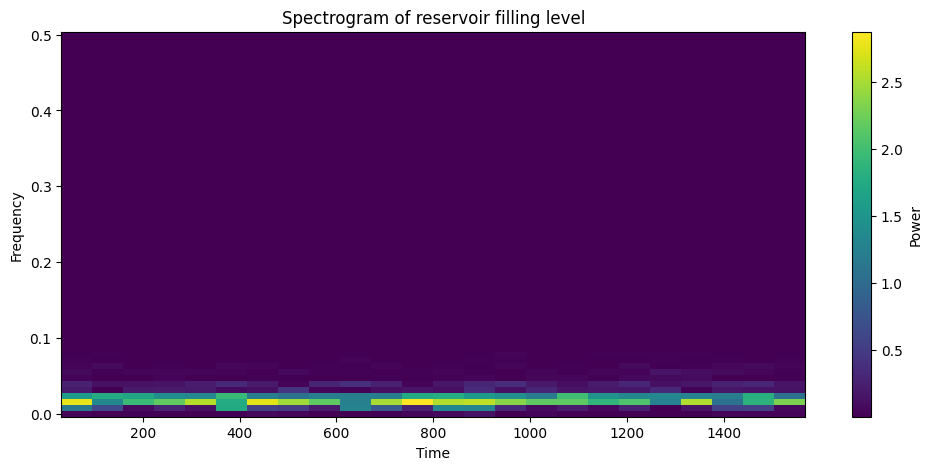

In [129]:
#tests the spectrogram function above
spectrogram_fig = spectrogram_analysis(
    stl_series,
    window_length=128,
    overlap=64
)

plt.show()

The spectrogram shows how the frequency content of the filling level changes over time.

Almost all of the signal power is concentrated at low frequencies, which can indicate that the  filling level is mainly influenced by slow and seasonal variations rather than rapid short term changes.

## AI Usage

In part 3 of the project i used AI for mostly the streamlit part especially for the Weather analysis part, page 5. I felt it was a bit to complex in the form of that it was alot to connect and get to work together so i used AI to help me extra during that part.  

On the notebook part i didnt use AI that much other than to explain me some stuff i did not understand and to help me with some part of the codes i got error codes with. 

## Log

In Part 3 i continued developing both the Jupyter Notebook and the Streamlit dashboard. I first reorganized the github repo based on the feedback from part 2. Then i started by creating a separate part3 branch so that the new work could be developed without changing the main branch directly.

The first task in the notebook part was to work with data from NVE. I downloaded shapefiles for the electricity bidding areas (budområder) and the NVE regions. Using geopandas, i loaded the shapefiles, checked their coordinate systems and converted them to longitude and latitude coordinates. I then created functions for randomly sampling 1000 locations inside each region. This was done for the electricity areas NO1 to NO5 and for the precipitation regions East, West and North. The NVE regions were combined where East consists of RS and RØ, while North consists of RM and RN as the task wanted. 

Next, i worked with the open meteo historical weather API. I created a function that takes a region and a time interval as input, selects one sampled location from the corresponding region and downloads hourly ERA5 weather data. For 2024 i got 8784 results (24 hourly data x 366 days). I then analysed the weather data. For precipitation, i calculated daily average values and used the DCT to create a high pass filter series. This seasonally adjusted variation was used together with robust statistics to create SPC boundaries and identify outliers. The DCT cutoff and number of robust standard deviations were added as parameters. For temperature, i calculated daily averages and used LOF to detect anomalies

After that i performed STL decomposition on the reservoir filling level data. The analysis separates the time series into trend, seasonal and residual components. The seasonal smoother, trend smoother and robust option were implemented as parameters. I also made a spectrogram to visually see the data. 

For the streamlit application i addedtwo new analysis pages. The Reservoir Analysis page contains STL and Spectrogram tabs, while the Weather Analysis page contains SPC and LOF tabs. The weather page was also connected to the same area logic used by the Magasinstatistikk data, so the selected reservoir area determines which weather region is used. Overall part3 of the project was understandable and straight forward, with some obstacles. 

